# Demo — Role 1: data, classical models and essay length
**Group 06 · CLC02 · Role 1**

Everything below is computed from the **saved outputs of the final project** (`MLA_Final/`): no model is re-trained and the official test labels are only read from saved prediction files.

**Run all cells top to bottom (Run All).** The raw PERSUADE test CSV is optional: if it is present the unit text is shown, otherwise the step says so (reading it takes ~20–40 s; cut that wait in the video).

Steps: ① reproduce the paper's tables → ② trace one real test unit → ③ identifier check → ④ Ineffective recall by essay length.

## 0 · Setup

In [1]:
import sys, hashlib, textwrap
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from sklearn.metrics import f1_score

# find the repo root from wherever the notebook is opened
HERE = Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "MLA_Final").is_dir())
sys.path.insert(0, str(ROOT / "VIDEO_CA_NHAN" / "build"))
sys.dont_write_bytecode = True
import make_visuals as data          # shared loaders: same numbers as the slides

pd.set_option("display.width", 140, "display.max_colwidth", 120)
LABELS = data.LABELS                  # Ineffective=0, Adequate=1, Effective=2

from IPython.display import HTML
def show(df, fmt=None, index=False):
    """Big, readable HTML table (no jinja2 needed)."""
    df = df.copy()
    for col, f in (fmt or {}).items():
        df[col] = df[col].map(lambda v, f=f: f.format(v) if isinstance(v, (int, float, np.number)) else v)
    display(HTML('<div style="font-size:18px; line-height:1.5">' + df.to_html(index=index) + "</div>"))

print("repo root:", ROOT)

repo root: C:\Users\Admin\Desktop\MLA


## ① Reproduce the paper's main tables from saved predictions
Look at the two **Random Forest (FS-B)** rows and the `[SUCCESS]` line.

In [2]:
import subprocess
out = subprocess.run([sys.executable, "reproduce_results.py"], cwd=ROOT / "MLA_Final" / "Code",
                     capture_output=True, text=True, encoding="utf-8")
print(out.stdout[-2200:])

-----------------------------------------------------------------------------
Test   | Majority (Adequate)        | 0.297    | 0.000    |   0.0%   | 0.892   | 0.000   |  80.4%
Test   | Random Forest (FS-B)       | 0.510    | 0.202    |  17.2%   | 0.870   | 0.457   |  78.5%
Test   | DeBERTa-v3 L0 (unit only)  | 0.561    | 0.339    |  37.2%   | 0.831   | 0.514   |  74.4%
Test   | DeBERTa-v3 L1 (locked)     | 0.577    | 0.368    |  41.5%   | 0.841   | 0.523   |  75.7%
Test   | DeBERTa-v3 Prompt-Aware    | 0.581    | 0.379    |  44.2%   | 0.838   | 0.526   |  75.4%

TABLE 2: Level 1 minus Level 0 on the Same Units (RQ2)
Metric                    | Validation (29,102 units)  | Official Test (93,677 units)
-----------------------------------------------------------------------------------
Macro-F1 delta            | +0.0087 (paper: +0.0087)       | +0.0159 (paper: +0.0159)
F1 Ineffective delta      | +0.0091 (paper: +0.0091)       | +0.0292 (paper: +0.0292)
F1 Adequate delta         | +0.010

## ② One real test unit: from the raw CSV to a prediction
Test `row_idx` 47,059 — a Position on *Facial action coding system*.

In [3]:
USE_RAW = data.raw_path("test").exists()      # set to False to skip the 1 GB-class CSV
raw_test = data.raw_optional("test", no_raw=not USE_RAW)
e = data.example("test", 47059, raw_test)
rf = data.probability_row("test", "rf_feature_set_b", 47059)
l1 = data.probability_row("test", "L1", 47059)
trace = pd.DataFrame([
    ("raw CSV record", f"{e['raw_record']:,}" if e["raw_record"] is not None else "(raw CSV not loaded)"),
    ("row_idx (after dropping unlabelled rows)", f"{int(e['row_idx']):,}"),
    ("prompt / type", f"{e['prompt_name']} / {e['discourse_type']}"),
    ("text", e["text"] or "(needs raw CSV)"),
    ("label string -> id", f"{LABELS[int(e['label'])]} -> {int(e['label'])}"),
    ("unit words / essay words", f"{int(e['unit_words'])} / {int(e['essay_word_count'])}"),
    ("essay-length quartile", e["length_q"]),
], columns=["step", "value"])
show(trace)
probs = pd.DataFrame({m: [f"{r['pred_proba_' + str(i)]:.3f}" for i in range(3)] + [LABELS[int(r.pred_label)]]
                      for m, r in [("Random Forest FS-B", rf), ("DeBERTa L1 (locked)", l1)]},
                     index=["P(Ineffective)", "P(Adequate)", "P(Effective)", "prediction"])
show(probs, index=True)

step,value
raw CSV record,"57,633"
row_idx (after dropping unlabelled rows),"47,059"
prompt / type,Facial action coding system / Position
text,That is all everything you need to know about Mona Lisa and her smile.
label string -> id,Ineffective -> 0
unit words / essay words,14 / 225
essay-length quartile,Q1 (<=315)


,Random Forest FS-B,DeBERTa L1 (locked)
P(Ineffective),0.544,0.978
P(Adequate),0.342,0.021
P(Effective),0.114,0.000
prediction,Ineffective,Ineffective


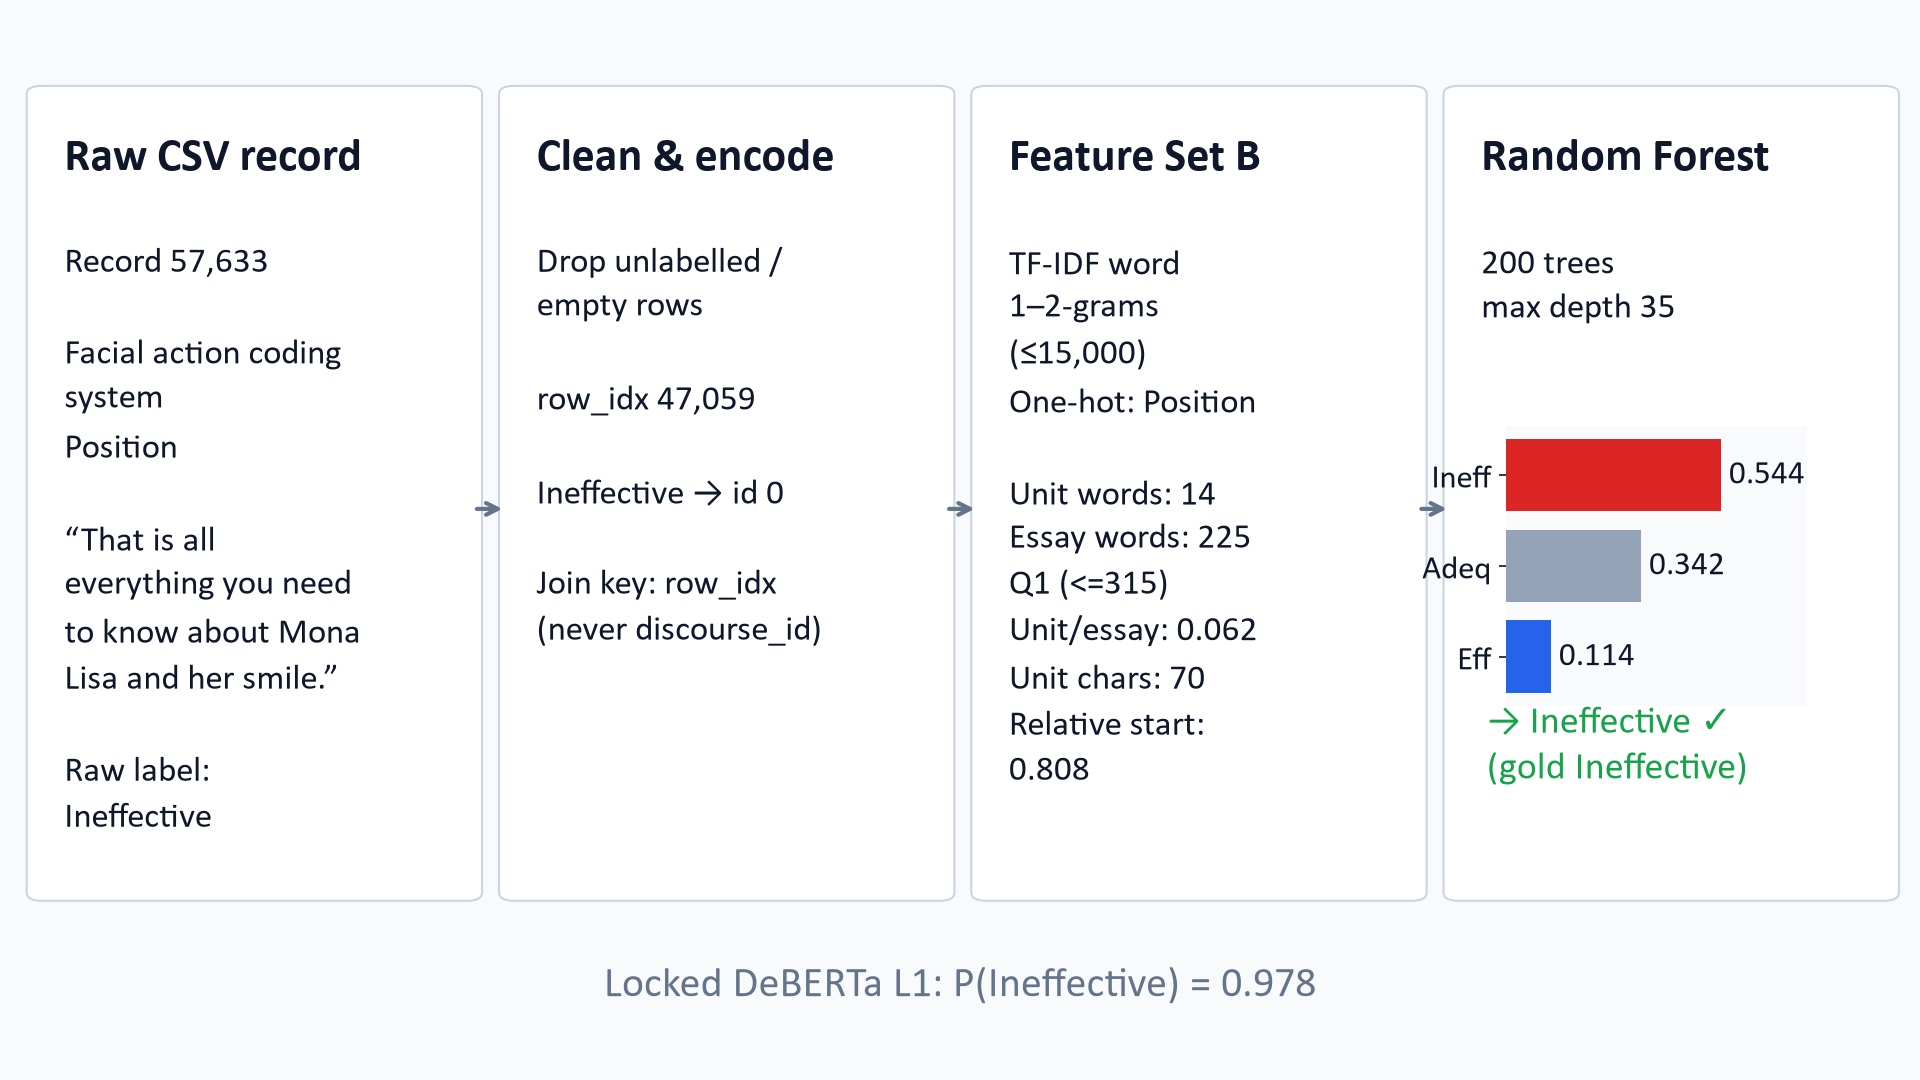

In [4]:
display(Image(filename=str(ROOT / "VIDEO_CA_NHAN/Nguoi_1_Data_Classical_Length/visuals/v1_example_trace_rf.png"), width=1100))

## ③ Why every join uses `row_idx`, never `discourse_id`

In [5]:
raw_train = data.raw_optional("train", no_raw=not USE_RAW)
if raw_train is None:
    r = data.table("D4_identifier_integrity.csv").query("file == 'train+val annotated'").iloc[0]
    n, distinct, src = int(r.units), int(r.distinct_discourse_id), "saved table D4"
else:
    n, distinct, src = len(raw_train), raw_train.discourse_id.nunique(), "raw train CSV"
print(f"annotated units: {n:,}   distinct discourse_id values: {distinct:,}   ({src})")
print("-> Excel rounded the IDs, so joining on discourse_id would mix up units.")

annotated units: 144,289   distinct discourse_id values: 728   (raw train CSV)
-> Excel rounded the IDs, so joining on discourse_id would mix up units.


## ④ Ineffective recall by essay-length quartile (official test, saved predictions)
New analysis for this video: computed here from the saved per-unit predictions.

In [6]:
rows = data.recalls()
recall = pd.DataFrame(rows, columns=["essay-length quartile", "gold Ineffective", "RF recall", "DeBERTa L1 recall", "RF caught"])
show(recall, {"gold Ineffective": "{:,}", "RF recall": "{:.1%}", "DeBERTa L1 recall": "{:.1%}"})
q, n, *_ , caught = rows[-1]
print(f"In the longest essays the Random Forest catches {caught} of {n} gold Ineffective units.")

essay-length quartile,gold Ineffective,RF recall,DeBERTa L1 recall,RF caught
Q1 (<=315),"2,384",23.3%,45.1%,555
Q2 (316-422),934,13.7%,38.4%,128
Q3 (423-566),598,6.9%,35.6%,41
Q4 (>=567),309,0.6%,35.0%,2


In the longest essays the Random Forest catches 2 of 309 gold Ineffective units.


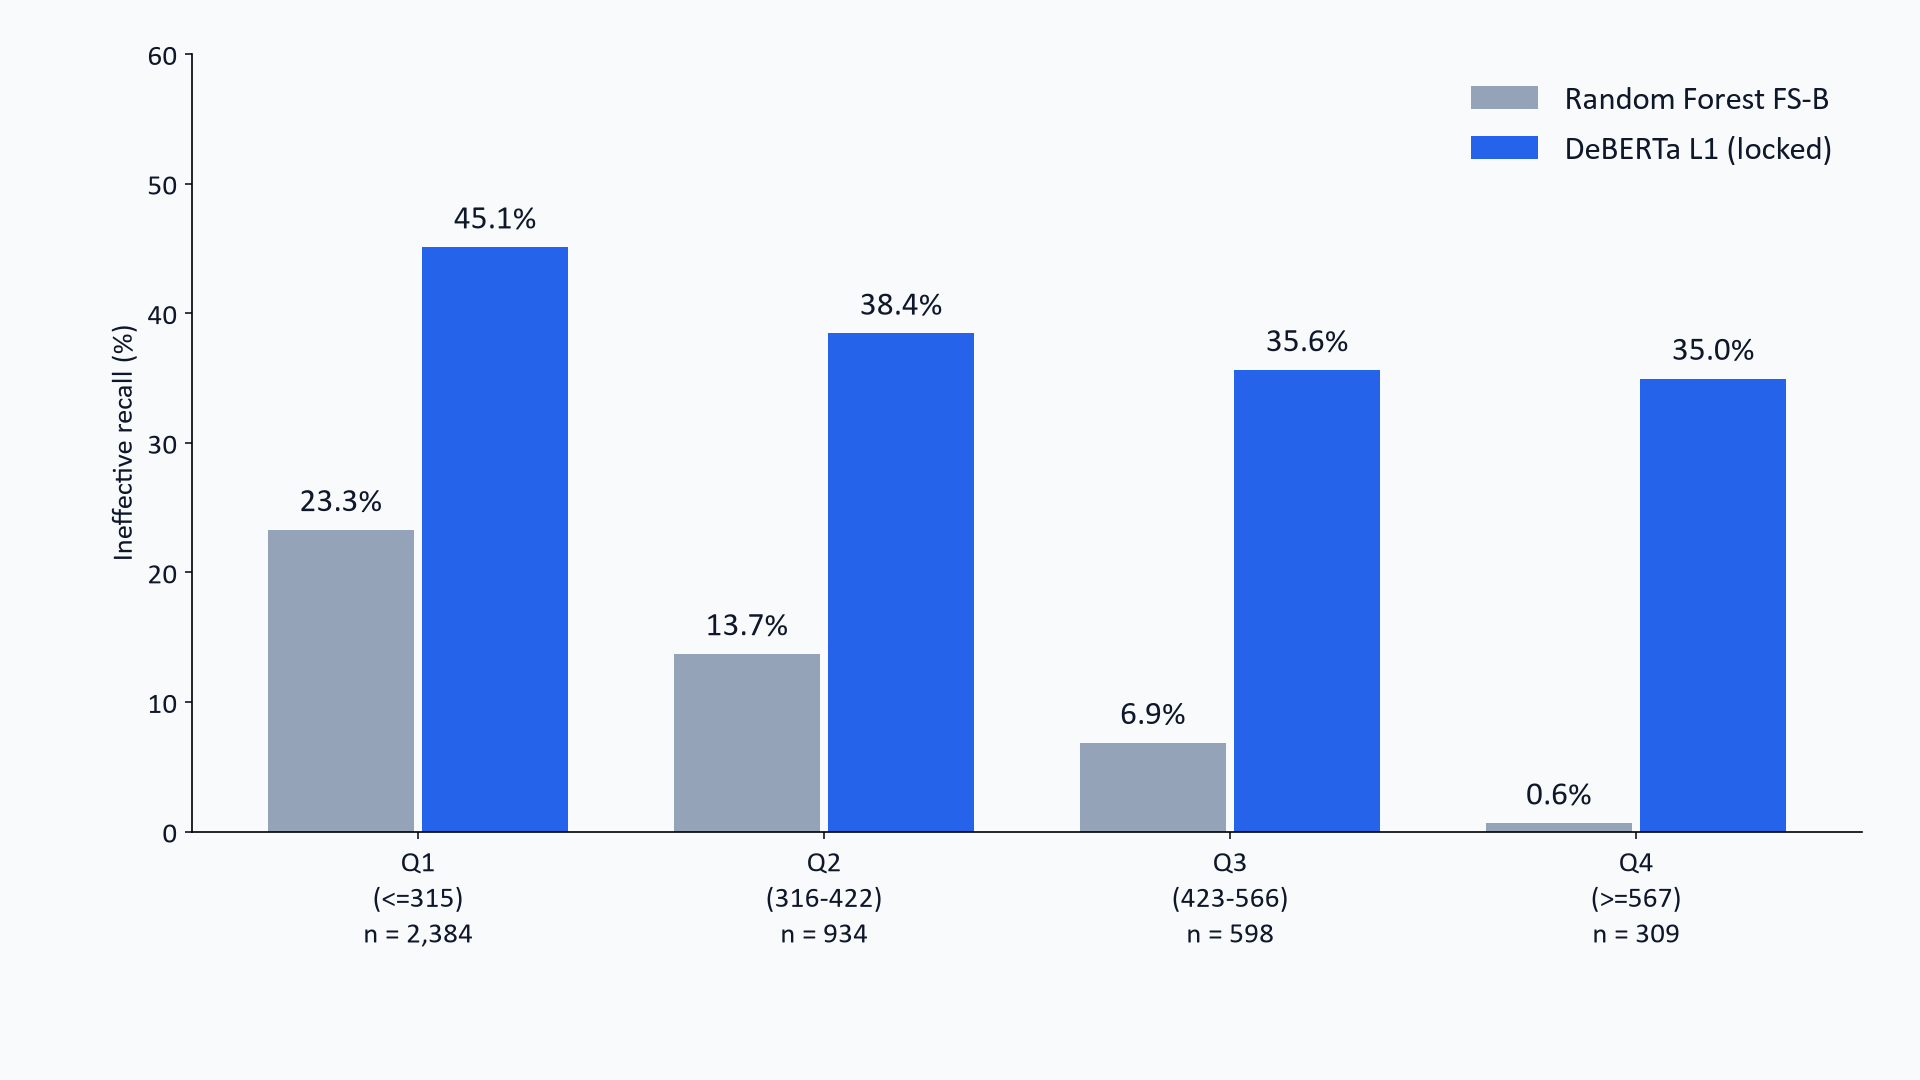

In [7]:
display(Image(filename=str(ROOT / "VIDEO_CA_NHAN/Nguoi_1_Data_Classical_Length/visuals/v2_rf_recall_by_length.png"), width=1000))